# Forecast Uncertainty from Bootstrapped Portfolio and Market Returns


| Part | Content |
|---|---|
| 1 | Data and setup |
| 2 | Theory and methods |
| 3 | Simulation, iid world |
| 4 | Robustness: fat tails, volatility clustering |
| 5 | Posterior and prior sensitivity |
| 6 | Real-data forecasts |
| 7 | Limitations and conclusion |

## Part 1. Data and setup
Log returns, the no-look-ahead rule, and summaries only: no raw records are shown.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.data import load_log_returns, upto, yearly_table, descriptives

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})

In [2]:
lr = load_log_returns()
print(f'{len(lr)} daily log returns per series, {lr.index[0].date()} to {lr.index[-1].date()}')
descriptives(lr).style.format({'mean_ann': '{:.3f}', 'vol_ann': '{:.3f}', 'skew': '{:.2f}', 'excess_kurtosis': '{:.2f}'})

1018 daily log returns per series, 2022-09-22 to 2026-10-13


,days,mean_ann,vol_ann,skew,excess_kurtosis
asset,,,,,
acct,1018,0.352,0.284,0.07,3.19
spy,1018,0.168,0.163,0.40,12.07
bnd,1018,0.003,0.073,0.17,1.30
gld,1018,0.198,0.206,-0.76,6.21


Annualised volatility is the daily standard deviation times $\sqrt{252}$. Fat tails show up as large excess kurtosis.

In [3]:
yearly_table(lr).style.format({c: '{:.2f}' for c in yearly_table(lr).columns if c.startswith('vol_')})

,days,vol_acct,vol_spy,vol_bnd,vol_gld
year,,,,,
2022,70,0.36,0.25,0.11,0.18
2023,250,0.27,0.14,0.08,0.14
2024,252,0.31,0.13,0.07,0.16
2025,250,0.29,0.20,0.06,0.21
2026,196,0.22,0.14,0.06,0.31


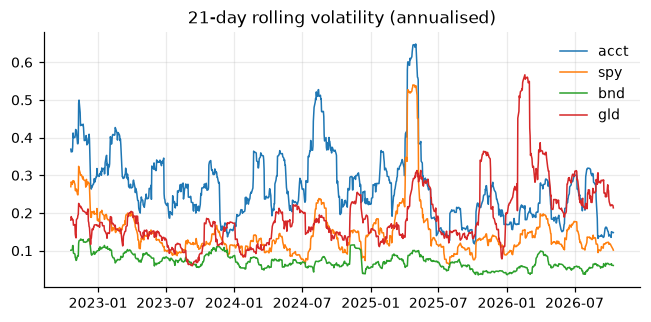

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
for a in C.ASSETS:
    ax.plot(lr.index, lr[a].rolling(21).std() * np.sqrt(C.N), label=a, lw=1)
ax.set(title='21-day rolling volatility (annualised)'); ax.legend(frameon=False); plt.show()

### Checks that must hold
Log returns add across days, and a forecast origin sees no later data.

In [5]:
simple = np.expm1(lr['acct'])
assert np.isclose(np.expm1(lr['acct'].sum()), (1 + simple).prod() - 1)       # log returns add up to the compounded return
h = upto(lr['acct'], '2024-12-31')
assert h.index.max() <= pd.Timestamp('2024-12-31') and len(h) < len(lr)       # no data after the origin
assert lr.index.is_monotonic_increasing and lr.notna().all().all()
print('checks passed')

checks passed


## Part 2. Methods and theory
Two bootstrap methods (`src/methods.py`) and one result (`src/theory.py`).

- **Simple bootstrap:** draw $H$ days with replacement from the history and add them up. Treats the historical mean as the true mean.
- **Mean-uncertainty bootstrap:** draw a pseudo-history of $n$ days first, then the $H$ forecast days from it, so the sample mean's uncertainty is carried along.

**Claim to check.** Under i.i.d. returns the forecast error has variance $H\sigma^2(1+H/n)$ while the simple bootstrap spreads only $H\sigma^2$, so its standard deviation is too small by $\sqrt{1+H/n}$. The mean-uncertainty bootstrap should be wider by that same factor.

In [6]:
from src import methods as M, theory as T

def sd_term(f, r, H, B, seed):
    return f(r, H, B, np.random.default_rng(seed))[:, -1].std()

# synthetic i.i.d. returns: the ratio of the two methods' spreads against sqrt(1 + H/n)
rows = []
for n in (250, 500, 1000):
    r = np.random.default_rng(C.SEED).normal(0.0005, 0.01, n)
    for H in (21, 63, 126, 252):
        sd_s = sd_term(M.simple, r, H, 10_000, C.SEED + 1)
        sd_m = sd_term(M.mean_uncertainty, r, H, 10_000, C.SEED + 2)
        rows.append(dict(n=n, H=H, H_over_n=H / n, simulated=sd_m / sd_s, theory=float(T.width_ratio(H, n))))
tab = pd.DataFrame(rows)
tab.style.format({'H_over_n': '{:.2f}', 'simulated': '{:.3f}', 'theory': '{:.3f}'}).hide(axis='index')

n,H,H_over_n,simulated,theory
250,21,0.08,1.015,1.041
250,63,0.25,1.104,1.119
250,126,0.50,1.209,1.226
250,252,1.01,1.407,1.417
500,21,0.04,1.023,1.021
500,63,0.13,1.060,1.061
500,126,0.25,1.110,1.119
500,252,0.50,1.220,1.226
1000,21,0.02,1.021,1.010
1000,63,0.06,1.031,1.031


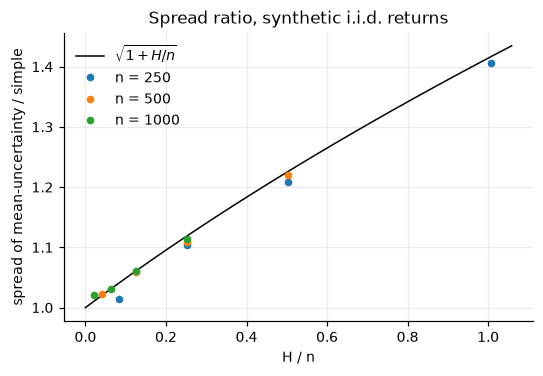

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
x = np.linspace(0, tab.H_over_n.max() * 1.05, 100)
ax.plot(x, np.sqrt(1 + x), 'k-', lw=1, label=r'$\sqrt{1+H/n}$')
for n, g in tab.groupby('n'):
    ax.plot(g.H_over_n, g.simulated, 'o', ms=4, label=f'n = {n}')
ax.set(xlabel='H / n', ylabel='spread of mean-uncertainty / simple', title='Spread ratio, synthetic i.i.d. returns')
ax.legend(frameon=False); plt.show()

The same check on the account's full history (one number per horizon; no daily values are shown).

In [8]:
r = lr['acct'].to_numpy(); n = len(r)
rows = []
for H in (63, 252):
    sd_s = sd_term(M.simple, r, H, C.B, C.SEED + 3)
    sd_m = sd_term(M.mean_uncertainty, r, H, C.B, C.SEED + 4)
    rows.append(dict(n=n, H=H, simple_sd=sd_s, mean_unc_sd=sd_m, ratio=sd_m / sd_s, theory=float(T.width_ratio(H, n))))
pd.DataFrame(rows).style.format({'simple_sd': '{:.3f}', 'mean_unc_sd': '{:.3f}', 'ratio': '{:.3f}', 'theory': '{:.3f}'}).hide(axis='index')

n,H,simple_sd,mean_unc_sd,ratio,theory
1018,63,0.141,0.145,1.028,1.030
1018,252,0.282,0.315,1.119,1.117


Predicted coverage of the simple bootstrap (Proposition 1) for a few $H/n$ values, at nominal 80% and 95%.

In [9]:
cov = pd.DataFrame({'H/n': [0.1, 0.25, 0.5, 1.0, 2.0]})
for lvl in (0.80, 0.95):
    cov[f'{int(lvl*100)}% band'] = T.coverage(lvl, cov['H/n'], 1)
cov.style.format({'H/n': '{:.2f}', '80% band': '{:.3f}', '95% band': '{:.3f}'}).hide(axis='index')

H/n,80% band,95% band
0.10,0.778,0.938
0.25,0.748,0.920
0.50,0.705,0.890
1.00,0.635,0.834
2.00,0.541,0.742
